# SPGER0046 — REVISÃO CIENTÍFICA ACESSÍVEL DA SEÇÃO 1

**Samuel Constantino Teixeira — 1.1 a 1.4.** Continuidade do notebook v2 de 26/10/2026, consolidada em 27/10/2026. Reaproveita o portfólio, as sete lentes, a recuperação de passagens e a rastreabilidade. A bibliometria anterior não é repetida.

Abra este arquivo dentro do pacote da Seção 1. Fora do pacote, a primeira célula recupera somente os arquivos públicos indispensáveis do repositório e confere seus hashes. PDFs de terceiros permanecem no acervo privado. As evidências já conferidas não são reclassificadas como nova leitura por uma reexecução.

## 1 — AMBIENTE E ENTRADAS

A verificação SHA-256 evita substituir silenciosamente a configuração ou os dados por outra versão. A rotina trabalha com a POA preparada do estudo, sem executar novamente a cadeia térmica ou elétrica.

In [1]:
from pathlib import Path
import sys, json, hashlib, urllib.request, importlib.util, subprocess

ROOTS = [Path.cwd(), Path.cwd().parent, Path.cwd()/"SPGER0046_Secao_01"]
BASE = next((p for p in ROOTS if (p/"src/solar_secao01.py").is_file()), Path.cwd()/"SPGER0046_Secao_01")
BASE.mkdir(parents=True, exist_ok=True)
for folder in ["manuscritos","figuras","apresentacao","documentacao","resultados"]:
    (BASE/folder).mkdir(exist_ok=True)
URL = "https://raw.githubusercontent.com/samuelasroma-byte/SPGER0046_Energias_Renovaveis/main/secoes/01_Recurso_Solar/producao/"
HASHES = {'src/solar_secao01.py': 'ab33d09626109d9cca6c0eecc0a69b939acad17d8a175fa66a6b07eb918097eb', 'src/curadoria_secao01.py': '38517e4eca0b714802c142324433167ea19edd7cc22638a025cfea82f46e9824', 'config/projeto.json': 'ece0ff6818af2b7cafd0f66bdb1eedc8cf1914c6aa2692eb1a7f68300031601a', 'dados/poa_15min.csv': '6e5d4753c2ab9dfa0cc20c38c8c9c1646a9444ea2561534ee61f92c6b6d5f8b5', 'bibliografia/Manifesto_Corpus_Secao_01.json': 'ebbd048f916481c4b885889675c3e5dd36f2c398e46dcbacbd807e7d3be32aa6', 'bibliografia/Protocolo_Analise_Sistemica.json': '9941f55c0b7c254be4fe4af1fa461dfbb36631d7b42d4df4529b8207b9c51e4b', 'bibliografia/Inventario_Fontes_Conferidas.json': '4d3fe38c45dfb1b8d43aa3a16fe227252122bfa3983274c36ab9965dbbcd95d8', 'bibliografia/Matriz_Evidencias.json': '41cdf631158dc247d8342e747c2c8c87dd26f56e79409a67afe1ed38aeb9fb2d', 'bibliografia/Selecao_Critica.json': '679684bd3482a1ec8facb796c94eaceb6f13c8baf24a89c557da0921134c0562', 'bibliografia/Status_Revisao.json': 'a478038bfd167c82323f10b54e28fde2059263967525ca02fbffc55965b812a1', 'bibliografia/Protocolo_Bibliometrico_Herdado.json': 'c74381019bc03ff5a6586c7fb52de86ec281c6b3b1f503bb8cac8a2667764aaf', 'bibliografia/Obras_Prioritarias_Herdadas.csv': '0d9a98d327cc40d654afbc1e25b6158e77027c6c1ae92d65e4014b4f606c1249', 'src/confrontar_evidencias.py': 'a0dbee2921bcf12db3490dc42f5d1cf44039d12ebcdf9fa3acaa1aad11c9ee21', 'src/finalizar_confronto.py': '8b16c393d8479649f5c8329f93915a4dbee5b6a002338ec897c007287f68c142', 'src/verificar_relacoes_fisicas.py': '2ff415f0242ee29f382e8bd082a440bf0c3c3633f975e997af267750d41589ce', 'src/exportar_editorial.py': '35c16559e6b9045b66929df370fa1a43e397958071b4bdd233ceaa352ebf15c7', 'src/editar_manuscritos.py': '93aecca93b39601e69ca87268b0512ffc7ea7d60fb88fa9cc7f7a8f2959f238a', 'src/preparar_slides.py': '54fb22dbd32b754e08cd69fe210ddb86f8ba271afe89d8929bf0f9f38867be31', 'bibliografia/Confronto_Cientifico_39_Evidencias.json': '70323c9cb861c2b3e4837365cbc8b2bddf49d8791192a43aa4cae40cca052507', 'bibliografia/Referencias_Verificadas.md': '86b89eda85c26f05d66fd579a95dcf087d25b570f8e0802eb03517c6931f47be', 'insumos/Base_Manuscrito_1_1.docx': '404eb99775d41caaec002c564f637a3673a2919b4c8faac0b262e6e02eaba9a5', 'apresentacao/Conteudo_6_Slides.json': 'eb67852dafc8f087067851ae5b2d8cf1330d7b2e55c6a73ce35fe4cb37a8b1a3', 'documentacao/Conferencia_Cientifica_39_Evidencias.md': 'e95e8c2507bbcc8691890457ada6129ea23f2de154088bc175588bec9bd3e71f', 'manuscritos/1_2_Grandezas_Radiometricas.md': '6bb893d1ebf7890fa63aa6fb0c3134ce2123c15bee8abe28dad9e3ce78ecb99a', 'manuscritos/1_3_Modulacao_Atmosferica.md': '421e84890458cf82510d14ab2fd11edb15b85f4b3ef8a90284ffa434b88ef7fa', 'manuscritos/1_4_Medicao_e_Estimativa.md': '592161c21f6067a616413b756941122952e05ff1057faafe56f972b46a84b6b6'}
for rel, expected in HASHES.items():
    p = BASE/rel
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(URL+rel) as response: data=response.read()
        assert hashlib.sha256(data).hexdigest()==expected, "Conteúdo remoto mudou: "+rel
        p.write_bytes(data)
    assert hashlib.sha256(p.read_bytes()).hexdigest()==expected, "Arquivo diferente do insumo conferido: "+rel
for mod, package in [("numpy","numpy>=2,<3"),("pandas","pandas>=2.2,<3"),("matplotlib","matplotlib>=3.9,<4"),("pvlib","pvlib==0.16.1"),("fitz","PyMuPDF>=1.24,<2"),("docx","python-docx>=1.1,<2")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable,"-m","pip","install","--quiet",package],check=True)
import pvlib
assert pvlib.__version__=="0.16.1", "Instale pvlib==0.16.1 e reinicie o kernel."
sys.path.insert(0,str(BASE/"src"))
print("Insumos e versão conferidos. Raiz:", BASE)


Insumos e versão conferidos. Raiz: /workspace/scratch/ae1684453e38/SPGER0046_Secao_01


## 2 — PORTFÓLIO E PROTOCOLO HERDADOS

Os códigos B e as 23 associações são os registros anteriores da Seção 1. A quarta edição do handbook é registrada como A045 e não como leitura presumida de B36/2021.

In [2]:
corpus=json.loads((BASE/"bibliografia/Manifesto_Corpus_Secao_01.json").read_text())
protocolo=json.loads((BASE/"bibliografia/Protocolo_Analise_Sistemica.json").read_text())
anterior=json.loads((BASE/"bibliografia/Protocolo_Bibliometrico_Herdado.json").read_text())
assert len(corpus["refs"])==12
assert sum(len(s["B_codes"]) for s in corpus["subsections"])==23
assert len(protocolo["lentes"])==7
import pandas as pd
prioritarias=pd.read_csv(BASE/"bibliografia/Obras_Prioritarias_Herdadas.csv")
print("Recorte B:",len(corpus["refs"]),"obras; 23 associações; sete lentes.")
print("Portfólio coletivo herdado:",len(prioritarias),"associações;",prioritarias["id"].nunique(),"obras distintas.")
print("Escopo do protocolo anterior:",anterior["scope"])
print("As contagens descrevem arquivos recuperados; não constituem uma nova busca ou leitura integral.")


Recorte B: 12 obras; 23 associações; sete lentes.
Portfólio coletivo herdado: 102 associações; 39 obras distintas.
Escopo do protocolo anterior: fundamentação teórica; sem busca de lacuna ou alegação de revisão sistemática
As contagens descrevem arquivos recuperados; não constituem uma nova busca ou leitura integral.


## 3 — FONTES E ESTADOS DE LEITURA

Disponibilidade, extração e leitura são estados diferentes. A lista registra arquivos e páginas conferidas. A reexecução valida a presença da matriz, mas não simula uma nova conferência intelectual.

In [3]:
inventario=json.loads((BASE/"bibliografia/Inventario_Fontes_Conferidas.json").read_text())
for f in inventario:
    print(f["codigo"],"|",f["status_leitura"],"| páginas PDF:",f["paginas_verificadas"])
assert sum(bool(f["paginas_verificadas"]) for f in inventario)==7
assert next(f for f in inventario if f["codigo"]=="B23")["leitura_integral"] is True


B12 | localizada | páginas PDF: [27, 28, 31, 33]
B23 | integral | páginas PDF: [1, 2]
B31 | localizada | páginas PDF: [1, 2]
B32 | localizada | páginas PDF: [16, 37, 38]
A045 | localizada | páginas PDF: [30, 34, 35, 36, 37, 38, 39, 58, 60, 61, 62, 161, 175, 202, 244, 245, 260, 267, 285, 286, 292, 325, 444, 445]
A003 | não lida | páginas PDF: []
B11 | localizada; metodologia e conclusões da inversão confrontadas | páginas PDF: [1, 9, 10, 11]
B36 | inspeção visual e textual; arquivo com defeitos; excluído como prova | páginas PDF: [26, 28, 29, 55]


## 4 — MATRIZ E SELEÇÃO CRÍTICA

A rotina preserva 39 evidências bibliográficas localizadas, suas páginas e hashes. O campo “CONFERIDA_LOCALIZADA” não significa leitura integral de toda a obra. As decisões mantêm explícitas as edições ausentes e as fontes ainda não lidas.

In [4]:
from finalizar_confronto import run as revisar_portfolio
evidencias,selecao,status,resumo_confronto=revisar_portfolio(root=BASE)
from confrontar_evidencias import validar_registros
print(validar_registros(root=BASE))
print("Confronto registrado:",resumo_confronto["por_classificacao"])
from verificar_relacoes_fisicas import run as verificar_fisica
relacoes=verificar_fisica(root=BASE)
assert relacoes["falhas"]==0
print("Relações físicas verificadas:",relacoes["total"])
assert len(evidencias)==39 and len(selecao)==14
assert all(e["arquivo_sha256"] and e["pagina_texto_sha256"] and e["pagina_pdf"] for e in evidencias)
print("Evidências por subseção:",dict(pd.Series([e["subsecao"] for e in evidencias]).value_counts().sort_index()))
print("Método:",status["metodo"])
print("Revisão sistemática integral concluída:",status["revisao_sistematica_integral_concluida"])


{'pareceres_de_leitura_registrados': 39, 'nova_leitura_alegada': False, 'verificacao_dos_PDFs_privados': 'Forneça fontes_dir para conferir hashes, páginas e trechos do acervo autorizado.'}
Confronto registrado: {'DIRETA': 16, 'DIRETA_COM_RESTRICAO': 18, 'DIRETA_COM_DERIVACAO': 1, 'DIRETA_COM_INFERENCIA': 4}
Relações físicas verificadas: 6
Evidências por subseção: {'1.1': np.int64(14), '1.2': np.int64(5), '1.3': np.int64(8), '1.4': np.int64(12)}
Método: revisão estruturada inspirada no ProKnow-C, com síntese crítica integrativa
Revisão sistemática integral concluída: False


## 5 — GEOMETRIA SOLAR E IRRADIÂNCIA EXTRATERRESTRE

A POA é observacional. SPA calcula ângulos e Spencer calcula irradiância extraterrestre. O caso permanece em America/Los_Angeles, com cálculo no meio de cada intervalo de 15 minutos. Os testes incluem o exemplo publicado do SPA, sem validar o sensor por essa comparação.

In [5]:
from solar_secao01 import run as calcular_geometria
dia,conferencia=calcular_geometria(root=BASE)
print("PVDAQ 2107 — 17/05/2024:",len(dia),"intervalos;")
print("POA não ausente:",conferencia["POA_observed_nonmissing_day"],"; intervalos com três amostras:",conferencia["POA_intervals_with_three_samples_day"])
print("SPA de referência: zenital aparente =",round(conferencia["reference_SPA_apparent_zenith_deg"],6),"°; azimute =",round(conferencia["reference_SPA_azimuth_deg"],6),"°")
print("Verificações:",", ".join(conferencia["checks_passed"]))


PVDAQ 2107 — 17/05/2024: 96 intervalos;
POA não ausente: 94 ; intervalos com três amostras: 68
SPA de referência: zenital aparente = 50.111622 °; azimute = 194.340241 °
Verificações: regular cadence, 91 days, no duplicate timestamps, Spencer independent expression, elevation+zenith, azimuth convention, night clipping, SPA published example


## 6 — FIGURA G01 E LIMITES OBSERVACIONAIS

O gráfico conserva lacunas e mostra 05h–21h no horário local, enquanto o CSV mantém o dia completo. A curva não demonstra céu claro nem isola efeitos de aerossóis ou nuvens. GHI/DNI/DHI locais independentes não estão presentes nessa seleção.

Figura vetorial: /workspace/scratch/ae1684453e38/SPGER0046_Secao_01/figuras/G01_recurso_geometria_escuro.pdf
Dados: /workspace/scratch/ae1684453e38/SPGER0046_Secao_01/resultados/G01_dados_verificados.csv


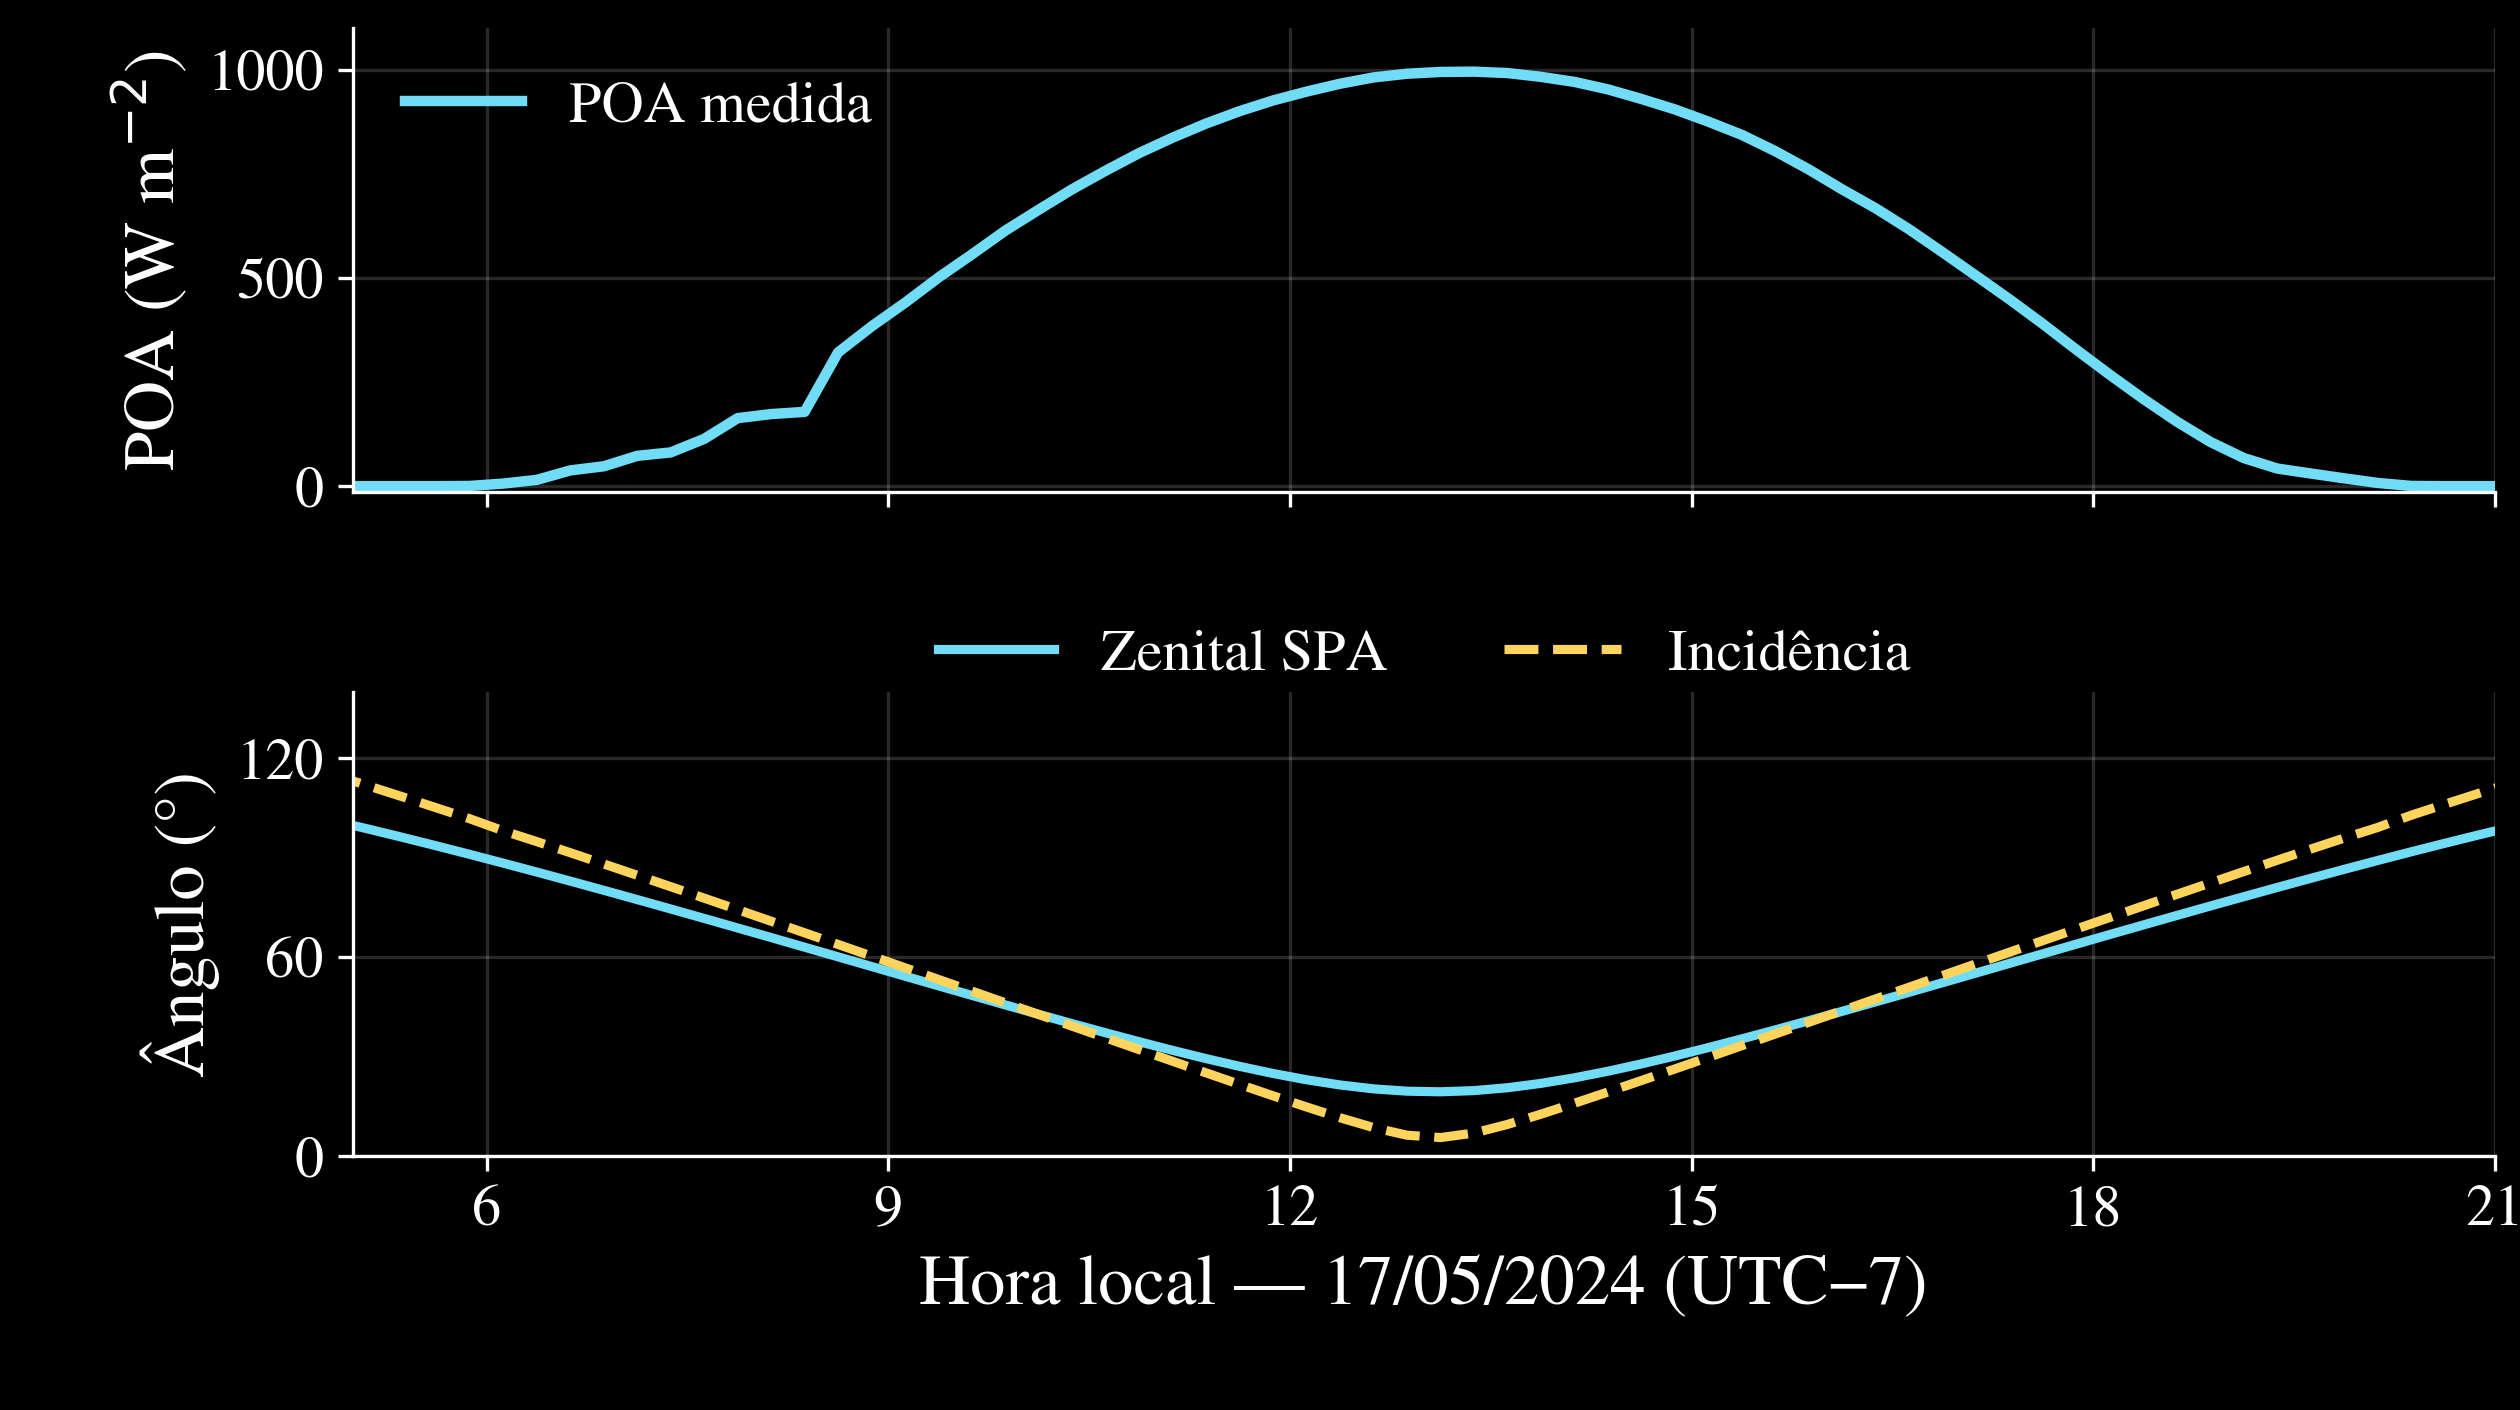

In [6]:
try:
    from IPython.display import display, Image, HTML
    display(Image(filename=str(BASE/"figuras/G01_recurso_geometria_escuro.png"),width=1050))
except ImportError:
    print("Visualização interativa indisponível neste executor; PNG/PDF foram exportados.")
print("Figura vetorial:",BASE/"figuras/G01_recurso_geometria_escuro.pdf")
print("Dados:",BASE/"resultados/G01_dados_verificados.csv")


## 7 — RECUPERAÇÃO DE PASSAGENS CANDIDATAS

A função abaixo reaproveita a busca local por descritores e a ideia de recuperação do notebook anterior. Ela é opcional, consulta somente PDFs autorizados e retorna candidatos com página e hash. Não realiza buscas bibliométricas externas, não aprova evidências e não reextrai arquivos quando existe cache. Consultas bilíngues reduzem o desencontro entre PDFs em inglês e perguntas em português.

In [7]:
import re, fitz
CONSULTAS={
 "1.1":"solar geometry zenith azimuth extraterrestrial Spencer geometria zenital",
 "1.2":"irradiance irradiation GHI DNI DHI POA radiometric irradiação",
 "1.3":"cloud aerosol precipitable water variability nuvens aerossóis",
 "1.4":"pyranometer pyrheliometer satellite reanalysis uncertainty medição incerteza"}
def candidatas_locais(pasta,subsecao,limite=8):
    pasta=Path(pasta); cache=BASE/"resultados/cache_privado";cache.mkdir(parents=True,exist_ok=True)
    tokens=set(CONSULTAS[subsecao].lower().split());result=[];vistos=set()
    for pdf in sorted(pasta.glob("*.pdf")):
        digest=hashlib.sha256(pdf.read_bytes()).hexdigest()
        if digest in vistos:continue
        vistos.add(digest);saved=cache/(digest+".json")
        if saved.exists():pages=json.loads(saved.read_text())
        else:
            with fitz.open(pdf) as d:pages=[p.get_text() for p in d]
            saved.write_text(json.dumps(pages,ensure_ascii=False))
        for n,text in enumerate(pages,1):
            score=sum(text.lower().count(t) for t in tokens)
            if score:result.append({"arquivo":pdf.name,"sha256":digest,"pagina_pdf":n,"pontuacao_lexical":score,"status":"CANDIDATA_NAO_CONFERIDA"})
    return sorted(result,key=lambda x:x["pontuacao_lexical"],reverse=True)[:limite]
print("Recuperação opcional definida; nenhuma nova busca ou extração foi acionada.")


Recuperação opcional definida; nenhuma nova busca ou extração foi acionada.


## 8 — PAINEL ACESSÍVEL DE ESTUDO

Texto grande, fundo escuro e navegação por subseção. O painel usa as evidências já conferidas; é uma forma de leitura da matriz e não uma etapa adicional de aprovação.

In [8]:
import html
parts=["<!doctype html><html lang='pt-BR'><meta charset='utf-8'><title>Seção 1 — estudo</title><style>body{background:#000000;color:#ffffff;font:26px 'Times New Roman',serif;max-width:1050px;margin:35px auto;padding:20px;line-height:1.5}h1,h2,a{color:#ffd45c}article{margin-bottom:35px}:focus{outline:4px solid #ffd45c}</style><h1>SEÇÃO 1 — EVIDÊNCIAS PARA ESTUDO</h1>"]
parts.append("<nav>"+" · ".join("<a href='#s"+s+"'>"+s+"</a>" for s in ["1.1","1.2","1.3","1.4"])+"</nav>")
for sec in ["1.1","1.2","1.3","1.4"]:
    parts.append("<h2 id='s"+sec+"'>SUBSEÇÃO "+sec+"</h2>")
    for e in [x for x in evidencias if x["subsecao"]==sec]:
        parts.append("<article><p>"+html.escape(e["afirmacao_parafraseada"])+"</p><p><b>"+e["fonte"]+" — "+html.escape(e["pagina_impressa"])+"; PDF "+str(e["pagina_pdf"])+".</b> "+html.escape(e["limites"])+"</p></article>")
parts.append("</html>")
painel=BASE/"resultados/Painel_Estudo_Acessivel.html";painel.write_text("\n".join(parts))
print("Painel acessível:",painel)


Painel acessível: /workspace/scratch/ae1684453e38/SPGER0046_Secao_01/resultados/Painel_Estudo_Acessivel.html


## 9 — MANUSCRITOS EDITÁVEIS E PDF

Esta célula gera os Word da 1.1 a 1.4, o integrado e o roteiro. A 1.1 preserva o manuscrito anterior. Pandoc produz equações nativas; LibreOffice exporta os PDFs de texto. Beamer/XeLaTeX compila os slides. Instale Pandoc, LibreOffice, XeLaTeX, Poppler e fontes URW antes de executar. Em Debian/Colab: `apt-get install pandoc libreoffice-writer texlive-xetex texlive-latex-extra fonts-urw-base35 poppler-utils`. A execução local não publica no Drive nem substitui o PPTX coletivo.

In [9]:
from exportar_editorial import exportar
editorial=exportar(root=BASE,gerar_pdf=True,gerar_beamer=True)
for arquivo in editorial["docx"]:
    assert (BASE/arquivo).is_file()
    print("Word editável:",arquivo)
print("Cadeia de exportação:",editorial["cadeia"])


Word editável: manuscritos/1_1_Geometria_Solar.docx
Word editável: manuscritos/1_2_Grandezas_Radiometricas.docx
Word editável: manuscritos/1_3_Modulacao_Atmosferica.docx
Word editável: manuscritos/1_4_Medicao_e_Estimativa.docx
Word editável: manuscritos/Secao_01_Integrada.docx
Word editável: apresentacao/Roteiro_Oral_6_Slides.docx
Word editável: documentacao/Conferencia_Cientifica_39_Evidencias.docx
Cadeia de exportação: {'1.1_DOCX': 'python-docx sobre manuscrito existente; equações OMML e novas equações via Pandoc', '1.2_a_1.4_DOCX': 'Markdown e LaTeX → Pandoc → Word com equações nativas', 'PDF_manuscritos': 'LibreOffice a partir dos DOCX', 'PDF_slides': 'Beamer → XeLaTeX'}


## 10 — CONFERÊNCIA DA EXECUÇÃO

Esta execução reproduz cálculos, registros do confronto, figuras, Word e PDF. Reexecutar não constitui nova leitura intelectual nem aprovação científica. Após qualquer edição, confira visualmente os arquivos. PDF e PPTX não possuem sincronização bidirecional.

In [10]:
assert conferencia["pvlib"]=="0.16.1"
assert (BASE/"resultados/Conferencia_Calculos.json").is_file()
assert (BASE/"bibliografia/Matriz_Evidencias.csv").is_file()
assert painel.is_file()
final={"execucao":"concluída","evidencias_confrontadas_registradas":len(evidencias),"verificacoes_fisicas":relacoes["total"],"DOCX_exportados":len(editorial["docx"]),"PDF_texto_exportados":len(editorial["pdf"]),"busca_bibliometrica_reexecutada":False,"revisao_integral_ProKnowC":False,"figura":"G01","quadros_da_11":6}
(BASE/"resultados/Conferencia_Notebook.json").write_text(json.dumps(final,ensure_ascii=False,indent=2))
print(json.dumps(final,ensure_ascii=False,indent=2))


{
  "execucao": "concluída",
  "evidencias_confrontadas_registradas": 39,
  "verificacoes_fisicas": 6,
  "DOCX_exportados": 7,
  "PDF_texto_exportados": 7,
  "busca_bibliometrica_reexecutada": false,
  "revisao_integral_ProKnowC": false,
  "figura": "G01",
  "quadros_da_11": 6
}
